# EEE3032 – Stage 8: Evaluate Deep Descriptors and Tune Late Fusion


**Research question:** does late fusion of a frozen ImageNet-pretrained MobileNetV3-Small descriptor with the selected SIFT-BoVW representation improve category-level retrieval on MSRC-v2 compared with either representation independently?

We compare a small, controlled grid of BoVW score weights:

`S_fused = α × S_BoVW + (1 − α) × S_deep`

- `α = 0.0`: deep-only control;
- `α = 1.0`: BoVW-only control;
- intermediate values: late fusion.

Both representations are L2-normalised, so their dot products are cosine similarities. We use the **same 100 development queries** to evaluate every setting and select `α`. The final test queries are not used in Stage 8.

## 1. Connect to the project and load the fixed split

Use the same paths as in Stages 6–7. The project root must contain `cvpr/`, `split_manifest.csv`, the Stage 5 BoVW feature files, the Stage 6 development results, and the Stage 7 deep descriptor caches.

In [1]:
from pathlib import Path
import sys
import csv
import json
import re
import numpy as np
import matplotlib.pyplot as plt

try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/cvpr_coursework/EEE3032_Coursework_Starter_v3"
)
DATASET_SOURCE = Path(
    "/content/drive/MyDrive/cvpr_coursework/MSRC_ObjCategImageDatabase_v2"
)

if not (PROJECT_ROOT / "cvpr" / "dataset.py").is_file():
    raise FileNotFoundError("Set PROJECT_ROOT to the folder containing cvpr/dataset.py.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from cvpr.dataset import load_split_records, read_rgb
from cvpr.evaluation import average_precision, precision_at_k, per_category_summary

MANIFEST = PROJECT_ROOT / "split_manifest.csv"
gallery, dev, _test_records = load_split_records(
    DATASET_SOURCE,
    manifest_path=MANIFEST,
    extract_dir=PROJECT_ROOT / "data",
)

assert len(gallery) == 391
assert len(dev) == 100

gallery_names = np.asarray([record.filename for record in gallery])
dev_names = np.asarray([record.filename for record in dev])
print(f"Gallery={len(gallery)}, development={len(dev)}")
print("Final test queries are not evaluated in this notebook.")

Mounted at /content/drive
Gallery=391, development=100
Final test queries are not evaluated in this notebook.


## 2. Set the experiment and select the core BoVW configuration

By default, the notebook reads `results/stage6_dev_overall.csv` and selects the BoVW configuration with the highest Stage 6 development mAP. This keeps the deep extension anchored to the selected core method rather than choosing a new core configuration here.

You can set `CORE_CONFIG_OVERRIDE` to a specific Stage 6 configuration if you have already made and documented a different selection. The default `None` uses the Stage 6 result file.

In [2]:
K = 100
P_AT_K = 10
ALPHAS = [0.0, 0.25, 0.50, 0.75, 1.0]

# Leave as None to select the highest-mAP BoVW row from Stage 6.
# Example manual override: "dense_root_opponentsift"
CORE_CONFIG_OVERRIDE = None

BOVW_FEATURES_DIR = PROJECT_ROOT / "bovw_features" / "stage5_dev"
STAGE6_RESULTS_DIR = PROJECT_ROOT / "results"
DEEP_CACHE_DIR = PROJECT_ROOT / "deep_features" / "stage7"
RESULTS_DIR = PROJECT_ROOT / "results"
VISUAL_DIR = RESULTS_DIR / "stage8_fusion_visual_examples"
VISUAL_DIR.mkdir(parents=True, exist_ok=True)

STAGE6_OVERALL_FILE = STAGE6_RESULTS_DIR / "stage6_dev_overall.csv"
if CORE_CONFIG_OVERRIDE is None:
    if not STAGE6_OVERALL_FILE.exists():
        raise FileNotFoundError(
            f"Cannot find {STAGE6_OVERALL_FILE}. Run Stage 6 first, or set "
            "CORE_CONFIG_OVERRIDE manually to your selected Stage 6 BoVW config."
        )
    with STAGE6_OVERALL_FILE.open("r", newline="", encoding="utf-8") as handle:
        stage6_rows = list(csv.DictReader(handle))
    stage6_bovw_rows = [row for row in stage6_rows if row.get("method_type") == "BoVW"]
    if not stage6_bovw_rows:
        raise ValueError("Stage 6 results contain no rows with method_type='BoVW'.")
    selected_stage6_row = max(stage6_bovw_rows, key=lambda row: float(row["mAP"]))
    CORE_CONFIG = selected_stage6_row["configuration"]
    print("Selected automatically from Stage 6:", CORE_CONFIG)
    print("Stage 6 development mAP:", float(selected_stage6_row["mAP"]))
else:
    CORE_CONFIG = CORE_CONFIG_OVERRIDE
    print("Using the manually specified Stage 6 configuration:", CORE_CONFIG)

if not BOVW_FEATURES_DIR.is_dir():
    raise FileNotFoundError(f"Stage 5 folder not found: {BOVW_FEATURES_DIR}")
if not DEEP_CACHE_DIR.is_dir():
    raise FileNotFoundError(f"Stage 7 deep cache folder not found: {DEEP_CACHE_DIR}. Run Stage 7 first.")

print("BoVW configuration:", CORE_CONFIG)
print("K:", K, "| P@K:", P_AT_K, "| alpha grid:", ALPHAS)

Selected automatically from Stage 6: dense_root_opponentsift
Stage 6 development mAP: 0.25111275784624837
BoVW configuration: dense_root_opponentsift
K: 100 | P@K: 10 | alpha grid: [0.0, 0.25, 0.5, 0.75, 1.0]


## 3. Load and validate the selected Stage 5 BoVW matrices

The BoVW feature file contains gallery and development vectors weighted with IDF fitted from gallery histograms only. We check the saved filename order, matrix sizes, finiteness and L2 norms before ranking.

In [3]:
BOVW_FILE = BOVW_FEATURES_DIR / f"{CORE_CONFIG}_K{K}.npz"
if not BOVW_FILE.exists():
    raise FileNotFoundError(f"Selected Stage 5 feature file not found: {BOVW_FILE}")

with np.load(BOVW_FILE, allow_pickle=False) as saved:
    saved_config = str(saved["configuration"].item())
    saved_k = int(saved["K"])
    bovw_gallery = np.asarray(saved["gallery_features"], dtype=np.float32)
    bovw_dev = np.asarray(saved["query_features"], dtype=np.float32)
    bovw_gallery_names = saved["gallery_filenames"].astype(str)
    bovw_dev_names = saved["query_filenames"].astype(str)

if saved_config != CORE_CONFIG:
    raise ValueError(f"Expected {CORE_CONFIG}, found {saved_config} in {BOVW_FILE.name}.")
if saved_k != K:
    raise ValueError(f"Expected K={K}, found K={saved_k} in {BOVW_FILE.name}.")
if not np.array_equal(bovw_gallery_names, gallery_names):
    raise ValueError("Stage 5 gallery filename order does not match the official split.")
if not np.array_equal(bovw_dev_names, dev_names):
    raise ValueError("Stage 5 development filename order does not match the official split.")
if bovw_gallery.shape != (391, K) or bovw_dev.shape != (100, K):
    raise ValueError(f"Unexpected BoVW shapes: {bovw_gallery.shape}, {bovw_dev.shape}")
if not np.isfinite(bovw_gallery).all() or not np.isfinite(bovw_dev).all():
    raise ValueError("The BoVW matrices contain non-finite values.")

# Stage 5 already performed TF-IDF weighting and L2 normalisation.
# Check the saved values, then normalise once more to remove tiny floating-point drift.
def l2_normalise_rows(matrix):
    matrix = np.asarray(matrix, dtype=np.float32)
    norms = np.linalg.norm(matrix, axis=1, keepdims=True)
    return matrix / np.maximum(norms, 1e-12)

bovw_gallery_norms = np.linalg.norm(bovw_gallery, axis=1)
bovw_dev_norms = np.linalg.norm(bovw_dev, axis=1)
if not np.allclose(bovw_gallery_norms[bovw_gallery_norms > 0], 1.0, atol=1e-4):
    raise ValueError("Stage 5 gallery BoVW vectors are not L2-normalised.")
if not np.allclose(bovw_dev_norms[bovw_dev_norms > 0], 1.0, atol=1e-4):
    raise ValueError("Stage 5 development BoVW vectors are not L2-normalised.")

bovw_gallery = l2_normalise_rows(bovw_gallery)
bovw_dev = l2_normalise_rows(bovw_dev)

print("Loaded BoVW gallery:", bovw_gallery.shape)
print("Loaded BoVW development:", bovw_dev.shape)
print("Zero BoVW rows (gallery/dev):", int(np.sum(bovw_gallery_norms == 0)), int(np.sum(bovw_dev_norms == 0)))

Loaded BoVW gallery: (391, 100)
Loaded BoVW development: (100, 100)
Zero BoVW rows (gallery/dev): 0 0


## 4. Load and validate the Stage 7 MobileNet descriptors

The Stage 7 caches hold gallery and development features separately. The loader maps rows by filename, checks the descriptor metadata and confirms that no query or gallery image is missing.

In [4]:
DEEP_DESCRIPTOR_NAME = "mobilenet_v3_small_l2"
DEEP_DIM = 576
DEEP_GALLERY_FILE = DEEP_CACHE_DIR / "mobilenet_v3_small_gallery.npz"
DEEP_DEV_FILE = DEEP_CACHE_DIR / "mobilenet_v3_small_dev.npz"


def load_deep_cache_in_record_order(cache_file, records, expected_dim, expected_descriptor_name):
    if not cache_file.exists():
        raise FileNotFoundError(f"Missing Stage 7 cache: {cache_file}. Run Stage 7 first.")

    with np.load(cache_file, allow_pickle=False) as saved:
        names = saved["filenames"].astype(str).tolist()
        features = np.asarray(saved["features"], dtype=np.float32)
        descriptor_name = str(saved["descriptor_name"].item())

    if descriptor_name != expected_descriptor_name:
        raise ValueError(
            f"Wrong descriptor metadata in {cache_file.name}: {descriptor_name}"
        )
    if features.ndim != 2 or features.shape[1] != expected_dim:
        raise ValueError(f"Wrong feature dimension in {cache_file.name}: {features.shape}")
    if len(names) != len(features) or len(set(names)) != len(names):
        raise ValueError(f"Invalid filename metadata in {cache_file.name}")
    if not np.isfinite(features).all():
        raise ValueError(f"Non-finite values in {cache_file.name}")

    lookup = {name: features[i] for i, name in enumerate(names)}
    expected_names = [record.filename for record in records]
    missing = [name for name in expected_names if name not in lookup]
    if missing:
        raise ValueError(f"{cache_file.name} is missing images: {missing[:5]}")
    if set(names) != set(expected_names):
        raise ValueError(f"{cache_file.name} contains filenames outside the requested split.")

    return np.vstack([lookup[name] for name in expected_names]).astype(np.float32)


deep_gallery = load_deep_cache_in_record_order(
    DEEP_GALLERY_FILE, gallery, DEEP_DIM, DEEP_DESCRIPTOR_NAME
)
deep_dev = load_deep_cache_in_record_order(
    DEEP_DEV_FILE, dev, DEEP_DIM, DEEP_DESCRIPTOR_NAME
)

deep_gallery_norms = np.linalg.norm(deep_gallery, axis=1)
deep_dev_norms = np.linalg.norm(deep_dev, axis=1)
if not np.allclose(deep_gallery_norms, 1.0, atol=1e-4):
    raise ValueError("Stage 7 gallery deep vectors are not L2-normalised.")
if not np.allclose(deep_dev_norms, 1.0, atol=1e-4):
    raise ValueError("Stage 7 development deep vectors are not L2-normalised.")

# Re-normalise to remove tiny numerical drift and guarantee cosine scores.
deep_gallery = l2_normalise_rows(deep_gallery)
deep_dev = l2_normalise_rows(deep_dev)

print("Loaded MobileNet gallery:", deep_gallery.shape)
print("Loaded MobileNet development:", deep_dev.shape)

Loaded MobileNet gallery: (391, 576)
Loaded MobileNet development: (100, 576)


## 5. Calculate cosine-similarity matrices

The dot product between two L2-normalised vectors is their cosine similarity. Each matrix has one row per development query and one column per gallery image. Larger values mean more similar images.

We use late fusion at the **score level**. We do not concatenate the 100-D BoVW vectors with the 576-D deep vectors, because the descriptors have different dimensions and potentially different feature distributions.

In [5]:
S_BOVW = bovw_dev @ bovw_gallery.T
S_DEEP = deep_dev @ deep_gallery.T

assert S_BOVW.shape == (len(dev), len(gallery))
assert S_DEEP.shape == (len(dev), len(gallery))
assert np.isfinite(S_BOVW).all() and np.isfinite(S_DEEP).all()

print("BoVW similarity matrix:", S_BOVW.shape)
print("Deep similarity matrix:", S_DEEP.shape)
print("BoVW cosine range:", (float(S_BOVW.min()), float(S_BOVW.max())))
print("Deep cosine range:", (float(S_DEEP.min()), float(S_DEEP.max())))

BoVW similarity matrix: (100, 391)
Deep similarity matrix: (100, 391)
BoVW cosine range: (0.0, 0.9943150877952576)
Deep cosine range: (-0.3608335256576538, 0.9718774557113647)


## 6. Evaluate a similarity matrix using the coursework AP and P@10 definitions

The starter evaluator accepts feature vectors and a distance function. Late fusion, however, combines query-to-gallery scores from two different feature spaces. The helper below therefore evaluates a precomputed query/gallery similarity matrix directly, while reusing the supplied `average_precision()` and `precision_at_k()` implementations. Relevance is still defined by the filename-prefix retrieval group.

In [6]:
def evaluate_similarity_matrix(query_records, gallery_records, similarity_matrix, k=10):
    """Evaluate descending query-to-gallery similarities using the coursework metrics."""
    scores = np.asarray(similarity_matrix, dtype=np.float64)
    if scores.shape != (len(query_records), len(gallery_records)):
        raise ValueError(
            f"Similarity shape {scores.shape} does not match "
            f"({len(query_records)}, {len(gallery_records)})."
        )
    if not np.isfinite(scores).all():
        raise ValueError("Similarity matrix contains non-finite values.")

    gallery_categories = np.asarray([record.category for record in gallery_records], dtype=int)
    rows = []
    for query_index, query_record in enumerate(query_records):
        # Stable sorting makes any exact ties deterministic.
        ranked_indices = np.argsort(-scores[query_index], kind="stable")
        relevance = gallery_categories[ranked_indices] == int(query_record.category)
        total_relevant = int(np.sum(gallery_categories == int(query_record.category)))

        rows.append({
            "filename": query_record.filename,
            "category": int(query_record.category),
            "AP": average_precision(relevance, total_relevant=total_relevant),
            f"P@{k}": precision_at_k(relevance, k=k),
        })

    ap_values = np.asarray([row["AP"] for row in rows], dtype=float)
    p_values = np.asarray([row[f"P@{k}"] for row in rows], dtype=float)
    summary = {
        "n_queries": len(rows),
        "mAP": float(ap_values.mean()),
        f"mean_P@{k}": float(p_values.mean()),
    }
    return summary, rows


# Pure controls: alpha=1 is the selected classical BoVW system; alpha=0 is deep-only.
bovw_summary, bovw_query_rows = evaluate_similarity_matrix(dev, gallery, S_BOVW, k=P_AT_K)
deep_summary, deep_query_rows = evaluate_similarity_matrix(dev, gallery, S_DEEP, k=P_AT_K)

print(f"Selected BoVW mAP: {bovw_summary['mAP']:.4f} | mean P@10: {bovw_summary['mean_P@10']:.4f}")
print(f"MobileNet-only mAP: {deep_summary['mAP']:.4f} | mean P@10: {deep_summary['mean_P@10']:.4f}")

Selected BoVW mAP: 0.2511 | mean P@10: 0.2910
MobileNet-only mAP: 0.6726 | mean P@10: 0.7350


## 7. Tune the late-fusion weight on development queries only

We test five pre-declared settings. The selected weight maximises development mAP; if two settings have the same mAP, higher mean P@10 is preferred. This is the only parameter tuned in the deep extension.

In [7]:
fusion_rows = []
fusion_query_rows = {}
fusion_group_rows = {}
fusion_similarity_matrices = {}

for alpha in ALPHAS:
    fused_similarity = alpha * S_BOVW + (1.0 - alpha) * S_DEEP
    summary, query_rows = evaluate_similarity_matrix(
        dev, gallery, fused_similarity, k=P_AT_K
    )
    group_rows = per_category_summary(query_rows, k=P_AT_K)

    if alpha == 0.0:
        label = "MobileNetV3-Small only"
    elif alpha == 1.0:
        label = f"BoVW only ({CORE_CONFIG})"
    else:
        label = f"Late fusion alpha={alpha:.2f}"

    fusion_rows.append({
        "method": label,
        "core_configuration": CORE_CONFIG,
        "alpha_bovw": float(alpha),
        "alpha_deep": float(1.0 - alpha),
        "mAP": float(summary["mAP"]),
        "mean_P@10": float(summary["mean_P@10"]),
        "n_queries": int(summary["n_queries"]),
    })
    fusion_query_rows[alpha] = query_rows
    fusion_group_rows[alpha] = group_rows
    fusion_similarity_matrices[alpha] = fused_similarity

# Deterministic tie-breaking: mAP first, then mean P@10, then alpha closest to 0.5.
best_row = max(
    fusion_rows,
    key=lambda row: (
        row["mAP"],
        row["mean_P@10"],
        -abs(row["alpha_bovw"] - 0.5),
    ),
)
BEST_ALPHA = float(best_row["alpha_bovw"])
BEST_FUSED_SIMILARITY = fusion_similarity_matrices[BEST_ALPHA]
BEST_FUSED_QUERY_ROWS = fusion_query_rows[BEST_ALPHA]
BEST_FUSED_GROUP_ROWS = fusion_group_rows[BEST_ALPHA]

print(f"{'Method':38s} {'alpha':>7s} {'mAP':>10s} {'Mean P@10':>12s}")
print("-" * 72)
for row in sorted(fusion_rows, key=lambda item: item["alpha_bovw"]):
    print(
        f"{row['method']:38s} {row['alpha_bovw']:7.2f} "
        f"{row['mAP']:10.4f} {row['mean_P@10']:12.4f}"
    )

print("\nSelected alpha:", BEST_ALPHA)
print(f"Selected development mAP: {best_row['mAP']:.4f}")
print(f"Selected development mean P@10: {best_row['mean_P@10']:.4f}")

Method                                   alpha        mAP    Mean P@10
------------------------------------------------------------------------
MobileNetV3-Small only                    0.00     0.6726       0.7350
Late fusion alpha=0.25                    0.25     0.6186       0.6770
Late fusion alpha=0.50                    0.50     0.4812       0.5440
Late fusion alpha=0.75                    0.75     0.3498       0.3990
BoVW only (dense_root_opponentsift)       1.00     0.2511       0.2910

Selected alpha: 0.0
Selected development mAP: 0.6726
Selected development mean P@10: 0.7350


## 8. Save the development results and the selected fusion setting

These CSV files preserve the overall, per-query and per-group development evidence. The JSON file records the selected weight. The chosen alpha must be frozen before the final test evaluation.

In [8]:
def save_rows_to_csv(rows, output_file):
    if not rows:
        raise ValueError(f"No rows to save to {output_file}")
    output_file.parent.mkdir(parents=True, exist_ok=True)
    with output_file.open("w", newline="", encoding="utf-8") as handle:
        writer = csv.DictWriter(handle, fieldnames=list(rows[0].keys()))
        writer.writeheader()
        writer.writerows(rows)


# The alpha grid includes both pure controls and all tested fusion settings.
overall_file = RESULTS_DIR / "stage8_dev_alpha_sweep.csv"
per_query_rows = []
per_group_rows = []
for alpha in ALPHAS:
    per_query_rows.extend([
        {
            "alpha_bovw": float(alpha),
            "alpha_deep": float(1.0 - alpha),
            **row,
        }
        for row in fusion_query_rows[alpha]
    ])
    per_group_rows.extend([
        {
            "alpha_bovw": float(alpha),
            "alpha_deep": float(1.0 - alpha),
            **row,
        }
        for row in fusion_group_rows[alpha]
    ])

per_query_file = RESULTS_DIR / "stage8_dev_per_query.csv"
per_group_file = RESULTS_DIR / "stage8_dev_per_group.csv"
save_rows_to_csv(fusion_rows, overall_file)
save_rows_to_csv(per_query_rows, per_query_file)
save_rows_to_csv(per_group_rows, per_group_file)

selection = {
    "model": "MobileNetV3-Small",
    "descriptor": DEEP_DESCRIPTOR_NAME,
    "deep_dimension": DEEP_DIM,
    "core_configuration": CORE_CONFIG,
    "core_vocabulary_size": K,
    "alpha_bovw": BEST_ALPHA,
    "alpha_deep": 1.0 - BEST_ALPHA,
    "development_mAP": float(best_row["mAP"]),
    "development_mean_P_at_10": float(best_row["mean_P@10"]),
    "alpha_grid": ALPHAS,
    "selection_rule": "highest development mAP; tie-break by mean P@10; then alpha closest to 0.5",
    "test_evaluated": False,
}
selection_file = RESULTS_DIR / "stage8_selected_fusion.json"
with selection_file.open("w", encoding="utf-8") as handle:
    json.dump(selection, handle, indent=2)

# Preserve the development similarity matrices for reproducibility and later plotting.
similarity_file = RESULTS_DIR / "stage8_dev_similarity_matrices.npz"
np.savez_compressed(
    similarity_file,
    gallery_filenames=gallery_names,
    dev_filenames=dev_names,
    bovw_similarity=S_BOVW.astype(np.float32),
    deep_similarity=S_DEEP.astype(np.float32),
    best_fused_similarity=BEST_FUSED_SIMILARITY.astype(np.float32),
    best_alpha=np.asarray(BEST_ALPHA, dtype=np.float32),
)

print("Saved overall results:", overall_file)
print("Saved per-query results:", per_query_file)
print("Saved per-group results:", per_group_file)
print("Saved selected alpha:", selection_file)
print("Saved similarity matrices:", similarity_file)

Saved overall results: /content/drive/MyDrive/cvpr_coursework/EEE3032_Coursework_Starter_v3/results/stage8_dev_alpha_sweep.csv
Saved per-query results: /content/drive/MyDrive/cvpr_coursework/EEE3032_Coursework_Starter_v3/results/stage8_dev_per_query.csv
Saved per-group results: /content/drive/MyDrive/cvpr_coursework/EEE3032_Coursework_Starter_v3/results/stage8_dev_per_group.csv
Saved selected alpha: /content/drive/MyDrive/cvpr_coursework/EEE3032_Coursework_Starter_v3/results/stage8_selected_fusion.json
Saved similarity matrices: /content/drive/MyDrive/cvpr_coursework/EEE3032_Coursework_Starter_v3/results/stage8_dev_similarity_matrices.npz


## 9. Plot the alpha sweep

The plots show whether fusion helps consistently or whether the best result is effectively one of the pure representations. Do not claim improvement unless an intermediate alpha actually beats the BoVW-only and deep-only controls on the development set.

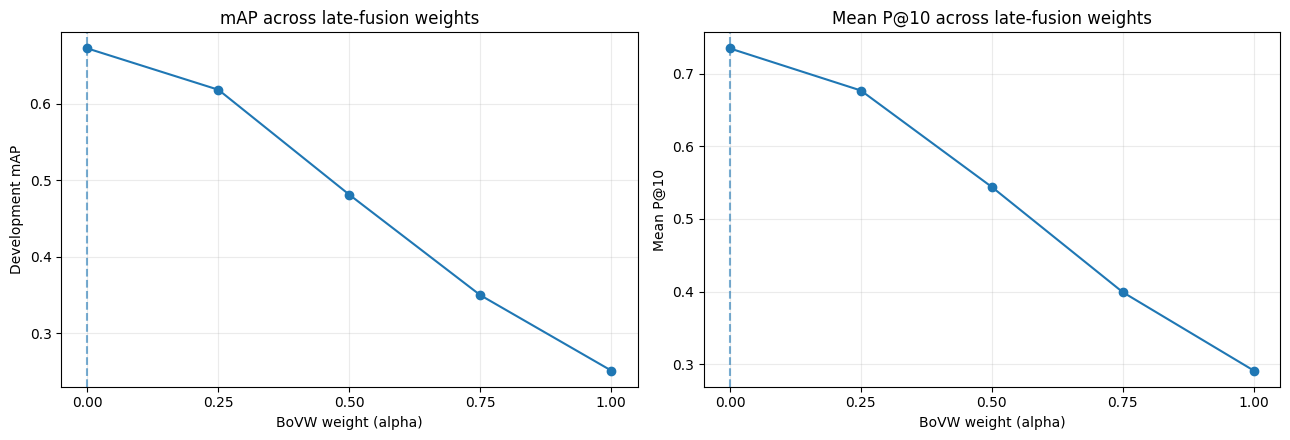

Saved: /content/drive/MyDrive/cvpr_coursework/EEE3032_Coursework_Starter_v3/results/stage8_dev_alpha_sweep.png


In [9]:
plot_rows = sorted(fusion_rows, key=lambda row: row["alpha_bovw"])
alpha_values = [row["alpha_bovw"] for row in plot_rows]
map_values = [row["mAP"] for row in plot_rows]
p10_values = [row["mean_P@10"] for row in plot_rows]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(alpha_values, map_values, marker="o")
axes[0].axvline(BEST_ALPHA, linestyle="--", alpha=0.6)
axes[0].set_xlabel("BoVW weight (alpha)")
axes[0].set_ylabel("Development mAP")
axes[0].set_title("mAP across late-fusion weights")
axes[0].set_xticks(ALPHAS)
axes[0].grid(alpha=0.25)

axes[1].plot(alpha_values, p10_values, marker="o")
axes[1].axvline(BEST_ALPHA, linestyle="--", alpha=0.6)
axes[1].set_xlabel("BoVW weight (alpha)")
axes[1].set_ylabel("Mean P@10")
axes[1].set_title("Mean P@10 across late-fusion weights")
axes[1].set_xticks(ALPHAS)
axes[1].grid(alpha=0.25)

fig.tight_layout()
alpha_plot_file = RESULTS_DIR / "stage8_dev_alpha_sweep.png"
fig.savefig(alpha_plot_file, dpi=180, bbox_inches="tight")
plt.show()
print("Saved:", alpha_plot_file)

## 10. Compare per-group behaviour

This table and heatmap help establish whether fusion changes retrieval across categories, rather than only changing the overall average. Each group has five development queries, so interpret these values as descriptive rather than as highly precise category estimates.

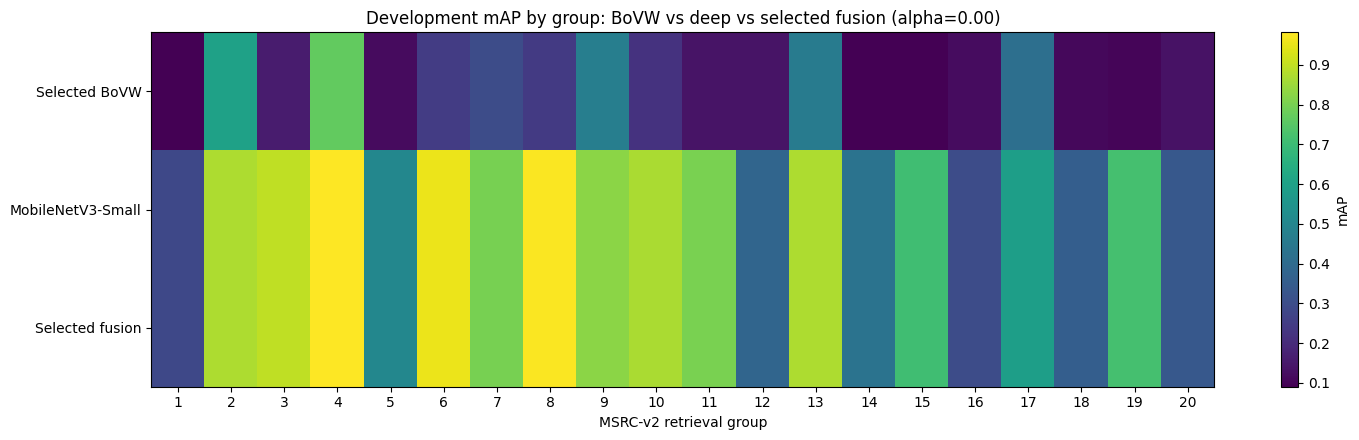

Saved group comparison: /content/drive/MyDrive/cvpr_coursework/EEE3032_Coursework_Starter_v3/results/stage8_dev_group_comparison_selected.csv
Saved group heatmap: /content/drive/MyDrive/cvpr_coursework/EEE3032_Coursework_Starter_v3/results/stage8_dev_group_comparison.png


In [10]:
core_group_rows = per_category_summary(bovw_query_rows, k=P_AT_K)
deep_group_rows = per_category_summary(deep_query_rows, k=P_AT_K)
best_group_rows = BEST_FUSED_GROUP_ROWS

core_group_lookup = {int(row["category"]): float(row["mAP"]) for row in core_group_rows}
deep_group_lookup = {int(row["category"]): float(row["mAP"]) for row in deep_group_rows}
fusion_group_lookup = {int(row["category"]): float(row["mAP"]) for row in best_group_rows}
categories = sorted(core_group_lookup)

comparison_rows = []
for category in categories:
    comparison_rows.append({
        "category": category,
        "BoVW_mAP": core_group_lookup[category],
        "Deep_mAP": deep_group_lookup[category],
        "Best_fusion_mAP": fusion_group_lookup[category],
        "Fusion_minus_BoVW": fusion_group_lookup[category] - core_group_lookup[category],
    })

comparison_file = RESULTS_DIR / "stage8_dev_group_comparison_selected.csv"
save_rows_to_csv(comparison_rows, comparison_file)

matrix = np.asarray([
    [core_group_lookup[c] for c in categories],
    [deep_group_lookup[c] for c in categories],
    [fusion_group_lookup[c] for c in categories],
], dtype=float)

fig, ax = plt.subplots(figsize=(15, 4.5))
image = ax.imshow(matrix, aspect="auto", interpolation="nearest")
ax.set_title(f"Development mAP by group: BoVW vs deep vs selected fusion (alpha={BEST_ALPHA:.2f})")
ax.set_xlabel("MSRC-v2 retrieval group")
ax.set_yticks([0, 1, 2])
ax.set_yticklabels(["Selected BoVW", "MobileNetV3-Small", "Selected fusion"])
ax.set_xticks(range(len(categories)))
ax.set_xticklabels(categories)
colourbar = fig.colorbar(image, ax=ax)
colourbar.set_label("mAP")
fig.tight_layout()

group_plot_file = RESULTS_DIR / "stage8_dev_group_comparison.png"
fig.savefig(group_plot_file, dpi=180, bbox_inches="tight")
plt.show()

print("Saved group comparison:", comparison_file)
print("Saved group heatmap:", group_plot_file)

## 11. Inspect representative ranked retrievals

We select one development query where the chosen fusion changes AP most positively relative to BoVW and one where it changes AP most negatively. For each query, the plot compares the query and the top five results from the selected BoVW method, MobileNetV3-Small, and the selected fusion.

In [11]:
bovw_ap = np.asarray([row["AP"] for row in bovw_query_rows], dtype=float)
deep_ap = np.asarray([row["AP"] for row in deep_query_rows], dtype=float)
fusion_ap = np.asarray([row["AP"] for row in BEST_FUSED_QUERY_ROWS], dtype=float)
ap_gain_vs_bovw = fusion_ap - bovw_ap

most_helped_index = int(np.argmax(ap_gain_vs_bovw))
most_harmed_index = int(np.argmin(ap_gain_vs_bovw))
example_indices = [most_helped_index, most_harmed_index]


def show_three_way_retrieval(query_index, top_k=5):
    query_record = dev[query_index]
    systems = [
        (f"BoVW: {CORE_CONFIG}", S_BOVW[query_index]),
        ("MobileNetV3-Small", S_DEEP[query_index]),
        (f"Fusion alpha={BEST_ALPHA:.2f}", BEST_FUSED_SIMILARITY[query_index]),
    ]

    fig, axes = plt.subplots(
        len(systems), top_k + 1,
        figsize=(3.0 * (top_k + 1), 3.1 * len(systems)),
    )

    for row_index, (label, scores) in enumerate(systems):
        axes[row_index, 0].imshow(read_rgb(query_record.path))
        axes[row_index, 0].set_title(
            f"QUERY\n{query_record.filename}\nGroup {query_record.category}",
            fontsize=9,
        )
        axes[row_index, 0].axis("off")
        axes[row_index, 0].set_ylabel(label, fontsize=9)

        ranked_indices = np.argsort(-scores, kind="stable")[:top_k]
        for rank, gallery_index in enumerate(ranked_indices, start=1):
            result_record = gallery[int(gallery_index)]
            relevant = int(result_record.category) == int(query_record.category)
            axes[row_index, rank].imshow(read_rgb(result_record.path))
            axes[row_index, rank].set_title(
                f"#{rank} | group {result_record.category}\n"
                f"{'Relevant' if relevant else 'Other group'}",
                fontsize=8,
            )
            axes[row_index, rank].axis("off")

    fig.suptitle(
        f"{query_record.filename} | group {query_record.category} | "
        f"fusion AP change vs BoVW: {ap_gain_vs_bovw[query_index]:+.3f}",
        fontsize=12,
    )
    fig.tight_layout()

    safe_name = re.sub(r"[^A-Za-z0-9_.-]+", "_", query_record.filename)
    output_file = VISUAL_DIR / f"stage8_query_{query_index:03d}_{safe_name}.png"
    fig.savefig(output_file, dpi=160, bbox_inches="tight")
    plt.show()
    print("Saved:", output_file)


for query_index in example_indices:
    print(
        f"\n{dev[query_index].filename} | group {dev[query_index].category} | "
        f"BoVW AP={bovw_ap[query_index]:.3f} | "
        f"Deep AP={deep_ap[query_index]:.3f} | "
        f"Fusion AP={fusion_ap[query_index]:.3f} | "
        f"Fusion change vs BoVW={ap_gain_vs_bovw[query_index]:+.3f}"
    )
    show_three_way_retrieval(query_index, top_k=5)

Output hidden; open in https://colab.research.google.com to view.